# Laser Cooling Simulator

Python companion to the AMO Toolkit page [Laser Cooling Simulator](https://amotoolkit.com/pages/cooling-simulator.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/cooling-simulator.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Doppler cooling force
Two counter-propagating beams, each with saturation s₀ and detuning δ (in units of Γ). Velocities in units of Γ/k, force in units of ħkΓ:
$F(v) = \frac{s_0/2}{1+s_0+4(\delta-v)^2} - \frac{s_0/2}{1+s_0+4(\delta+v)^2}$. Near v = 0 it is a friction $F \approx -\alpha v$. (Adding the two beams' rates ignores saturation cross-talk, the usual low-intensity approximation.)

damping at the page's defaults (δ = −0.5, s₀ = 0.5): α = 0.320 ħk²
page's secant estimate −F(0.1)/0.1 = 0.318

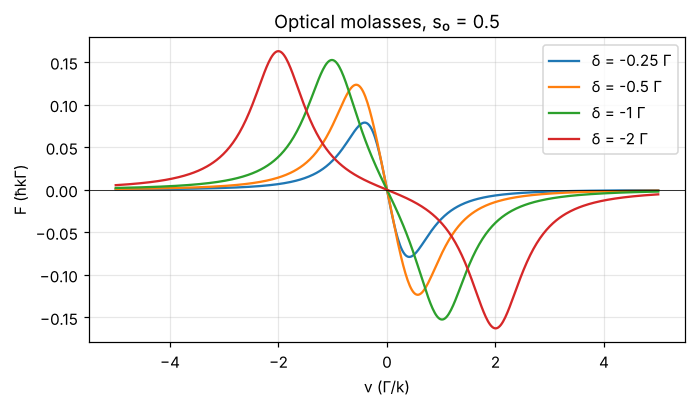

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def force(v, delta=-0.5, s0=0.5):
    return 0.5 * s0 / (1 + s0 + (2 * (delta - v)) ** 2) - 0.5 * s0 / (1 + s0 + (2 * (delta + v)) ** 2)

def damping(delta=-0.5, s0=0.5, dv=1e-6):
    return -(force(dv, delta, s0) - force(-dv, delta, s0)) / (2 * dv)

v = np.linspace(-5, 5, 501)
for d in (-0.25, -0.5, -1, -2):
    plt.plot(v, force(v, d), label=f"δ = {d} Γ")
plt.axhline(0, c="k", lw=0.5); plt.xlabel("v (Γ/k)"); plt.ylabel("F (ħkΓ)"); plt.legend(); plt.title("Optical molasses, s₀ = 0.5")
alpha_def = damping()
print(f"damping at the page's defaults (δ = −0.5, s₀ = 0.5): α = {alpha_def:.3f} ħk²")
print(f"page's secant estimate −F(0.1)/0.1 = {-force(0.1)/0.1:.3f}")

## 2. Damping is not temperature
The damping peaks near |δ| = Γ/2√3 at low intensity, while the Doppler temperature $T \propto (1+4\delta^2)/4|\delta|$ is lowest at |δ| = Γ/2 (course problem, week 5).

damping max at |δ| = 0.304 Γ (1/2√3 = 0.289); T min at |δ| = 0.498 Γ

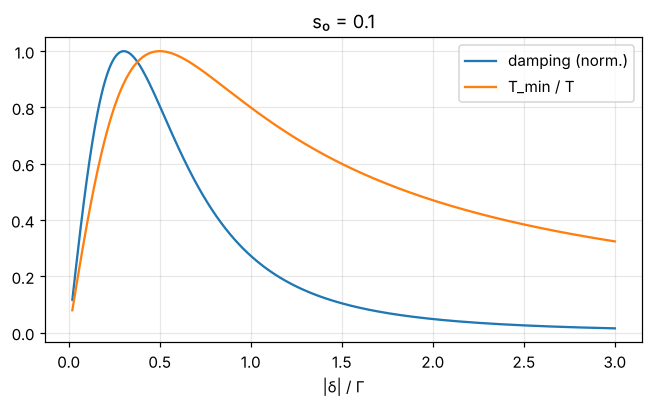

In [2]:
d = np.linspace(-3, -0.02, 600)
al = np.array([damping(x, 0.1) for x in d]); T = (1 + (2 * d) ** 2) / (4 * np.abs(d))
plt.plot(-d, al / al.max(), label="damping (norm.)"); plt.plot(-d, T.min() / T, label="T_min / T")
plt.xlabel("|δ| / Γ"); plt.legend(); plt.title("s₀ = 0.1")
print(f"damping max at |δ| = {-d[al.argmax()]:.3f} Γ (1/2√3 = {1/(2*np.sqrt(3)):.3f}); T min at |δ| = {-d[T.argmin()]:.3f} Γ")

## 3. Sidebands and cooling to the ground state
Lamb–Dicke sideband strengths for a thermal state with ⟨n⟩: k-th red ∝ (η²⟨n⟩)<sup>k</sup>/k!, k-th blue ∝ (η²(⟨n⟩+1))<sup>k</sup>/k!, carrier ≈ 1 − η²(2⟨n⟩+1). Resolved-sideband cooling then relaxes exponentially to the floor ¼(Γ/ω)²(α + ¼) with α = 1 (Phatak et al. 2024, Eq. 38).

{-4: 0.0, -3: 0.0002, -2: 0.0063, -1: 0.1125, 0: 0.7525, 1: 0.135, 2: 0.0091, 3: 0.0004, 4: 0.0}

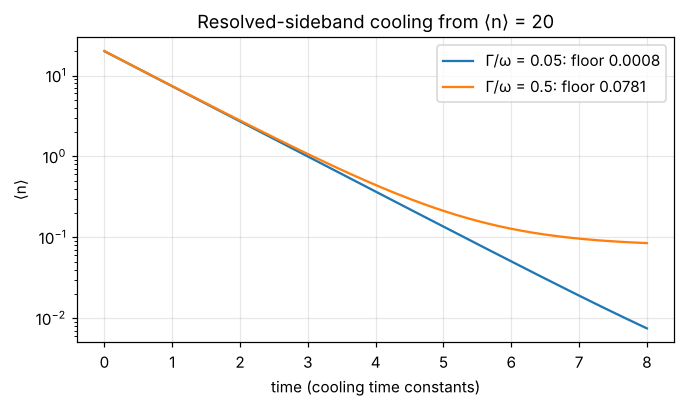

In [3]:
def sidebands(nbar=5, eta=0.15):
    from math import factorial
    out = {0: max(0, 1 - eta**2 * (2 * nbar + 1))}
    for k in range(1, 5):
        out[k] = (eta**2 * (nbar + 1)) ** k / factorial(k); out[-k] = (eta**2 * nbar) ** k / factorial(k)
    return dict(sorted(out.items()))
print({k: round(v, 4) for k, v in sidebands().items()})
t = np.linspace(0, 8, 200)
for gc in (0.05, 0.5):
    nss = 0.25 * gc**2 * 1.25
    plt.semilogy(t, nss + (20 - nss) * np.exp(-t), label=f"Γ/ω = {gc}: floor {nss:.4f}")
plt.xlabel("time (cooling time constants)"); plt.ylabel("⟨n⟩"); plt.legend(); plt.title("Resolved-sideband cooling from ⟨n⟩ = 20")

## 4. Check against the page

In [4]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(alpha_default=-force(0.1) / 0.1, alpha_low_s=-force(0.1, -0.3, 0.1) / 0.1)
DECIMALS = dict(alpha_default=3, alpha_low_s=3)
page = dict(alpha_default=0.318, alpha_low_s=0.109)
check(ours, page)

alpha_default: notebook 0.3179       page 0.318      OK
 alpha_low_s: notebook 0.1095       page 0.109      OK
All values match the page.